In [21]:
import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)

print("Project environment is ready!")

Pandas: 3.1.1
NumPy: 2.5.5
SciPy: 1.18.1
Project environment is ready!


In [22]:
import urllib.request
import zipfile
import certifi
import ssl
import os

# Dataset URL
url = "https://files.grouplens.org/datasets/movielens/ml-1m.zip"

# Create data directory
os.makedirs("data", exist_ok=True)

# SSL certificate configuration
ssl_context = ssl.create_default_context(cafile=certifi.where())

# Download dataset
zip_path = "data/ml-1m.zip"

with urllib.request.urlopen(url, context=ssl_context) as response:
    with open(zip_path, "wb") as file:
        file.write(response.read())

# Extract dataset
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("data")

print("MovieLens 1M downloaded and extracted successfully!")

MovieLens 1M downloaded and extracted successfully!


In [23]:
import pandas as pd
import numpy as np
import os

DATA_DIR = "data/ml-1m"

print(os.listdir(DATA_DIR))


['movies.dat', 'ratings.dat', 'README', 'users.dat']


In [24]:
ratings = pd.read_csv(
    f"{DATA_DIR}/ratings.dat",
    sep="::",
    engine="python",
    encoding="latin-1",
    names=["user_id", "movie_id", "rating", "timestamp"]
)

movies = pd.read_csv(
    f"{DATA_DIR}/movies.dat",
    sep="::",
    engine="python",
    encoding="latin-1",
    names=["movie_id", "title", "genres"]
)

users = pd.read_csv(
    f"{DATA_DIR}/users.dat",
    sep="::",
    engine="python",
    encoding="latin-1",
    names=["user_id", "gender", "age", "occupation", "zip_code"]
)

In [25]:
print("Ratings:", ratings.shape)
print("Movies:", movies.shape)
print("Users:", users.shape)


Ratings: (1000209, 4)
Movies: (3883, 3)
Users: (6040, 5)


In [26]:
print("RATINGS")
ratings.info()

print("\nMOVIES")
movies.info()

print("\nUSERS")
users.info()


RATINGS
<class 'pandas.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   user_id    1000209 non-null  int64
 1   movie_id   1000209 non-null  int64
 2   rating     1000209 non-null  int64
 3   timestamp  1000209 non-null  int64
dtypes: int64(4)
memory usage: 30.5 MB

MOVIES
<class 'pandas.DataFrame'>
RangeIndex: 3883 entries, 0 to 3882
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   movie_id  3883 non-null   int64
 1   title     3883 non-null   str  
 2   genres    3883 non-null   str  
dtypes: int64(1), str(2)
memory usage: 91.1 KB

USERS
<class 'pandas.DataFrame'>
RangeIndex: 6040 entries, 0 to 6039
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   user_id     6040 non-null   int64
 1   gender      6040 non-null   str  
 2   age         60

In [27]:
print("RATINGS")
print(ratings.isnull().sum())

print("\nMOVIES")
print(movies.isnull().sum())

print("\nUSERS")
print(users.isnull().sum())


RATINGS
user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64

MOVIES
movie_id    0
title       0
genres      0
dtype: int64

USERS
user_id       0
gender        0
age           0
occupation    0
zip_code      0
dtype: int64


In [28]:
print("Ratings duplicates:", ratings.duplicated().sum())
print("Movies duplicates:", movies.duplicated().sum())
print("Users duplicates:", users.duplicated().sum())


Ratings duplicates: 0
Movies duplicates: 0
Users duplicates: 0


In [29]:
print(
    "Duplicate user-movie pairs:",
    ratings.duplicated(subset=["user_id", "movie_id"]).sum()
)


Duplicate user-movie pairs: 0


### Data Quality Check

The MovieLens 1M dataset was checked for missing values and duplicate records.

**Results:**
- No missing values in any of the three datasets.
- No duplicate records in ratings, movies, or users.
- No duplicate user-movie pairs.

**Conclusion:**

The dataset is clean with respect to missing values and duplicates. No cleaning operations are required for these checks. Further validation of rating ranges and relationships between datasets will be performed before model development.

In [50]:
# 1. Check rating range

print("Minimum rating:", ratings["rating"].min())
print("Maximum rating:", ratings["rating"].max())

print("Invalid ratings:",
      (~ratings["rating"].between(1, 5)).sum())


# 2. Check unique IDs

print("\nUnique users in ratings:", ratings["user_id"].nunique())
print("Users in users dataset:", users["user_id"].nunique())

print("Unique movies in ratings:", ratings["movie_id"].nunique())
print("Movies in movies dataset:", movies["movie_id"].nunique())


# 3. Check referential integrity

missing_users = set(ratings["user_id"]) - set(users["user_id"])
missing_movies = set(ratings["movie_id"]) - set(movies["movie_id"])

print("\nUsers missing from users dataset:", len(missing_users))
print("Movies missing from movies dataset:", len(missing_movies))

Minimum rating: 1
Maximum rating: 5
Invalid ratings: 0

Unique users in ratings: 6040
Users in users dataset: 6040
Unique movies in ratings: 3706
Movies in movies dataset: 3883

Users missing from users dataset: 0
Movies missing from movies dataset: 0


In [46]:
ratings["rating"].describe()

count    1.000209e+06
mean     3.581564e+00
std      1.117102e+00
min      1.000000e+00
25%      3.000000e+00
50%      4.000000e+00
75%      4.000000e+00
max      5.000000e+00
Name: rating, dtype: float64

In [47]:
print(ratings["rating"].value_counts().sort_index())

rating
1     56174
2    107557
3    261197
4    348971
5    226310
Name: count, dtype: int64


In [48]:
rating_distribution = ratings["rating"].value_counts().sort_index()

rating_percentage = (
    ratings["rating"].value_counts(normalize=True).sort_index() * 100
)

rating_summary = pd.DataFrame({
    "Count": rating_distribution,
    "Percentage": rating_percentage
})

display(rating_summary.round(2))


,Count,Percentage
rating,,
1,56174,5.62
2,107557,10.75
3,261197,26.11
4,348971,34.89
5,226310,22.63


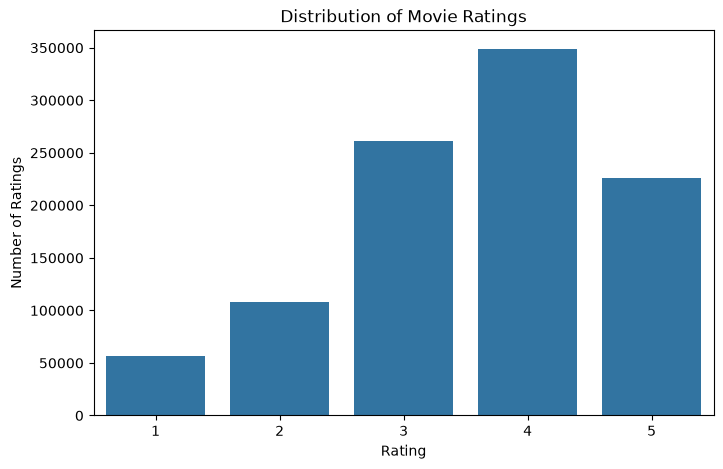

In [49]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=ratings,
    x="rating"
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")

plt.show()

### Rating Distribution Analysis

The MovieLens 1M dataset contains 1,000,209 ratings on a scale from 1 to 5.

**Key findings:**
- The most frequent rating is 4 (34.89%).
- Ratings of 4 and 5 account for 57.52% of all ratings.
- Ratings of 1 and 2 account for 16.37%.
- The average rating is 3.58, while the median is 4.

**Conclusion:**

The rating distribution is positively skewed, indicating that users tend to give higher ratings more frequently than lower ratings. This positive rating bias should be considered when developing and evaluating recommendation models.

In [51]:
# Number of ratings per user

user_activity = ratings.groupby("user_id")["rating"].count()

print(user_activity.describe())

count    6040.000000
mean      165.597517
std       192.747029
min        20.000000
25%        44.000000
50%        96.000000
75%       208.000000
max      2314.000000
Name: rating, dtype: float64


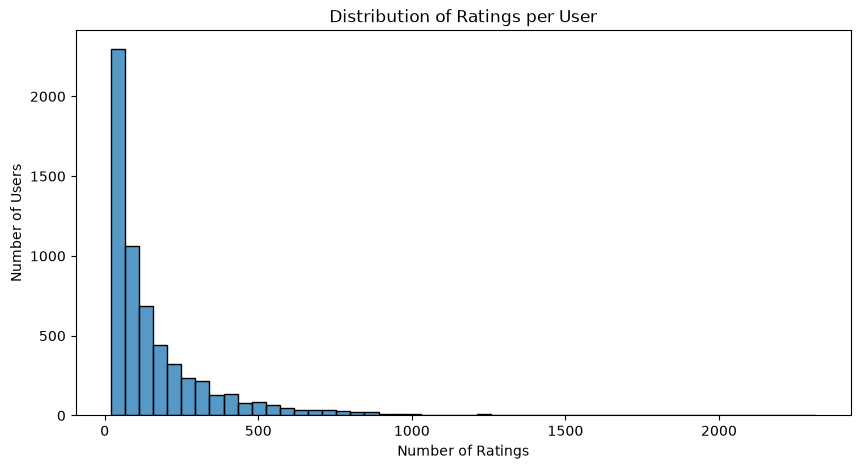

In [52]:
plt.figure(figsize=(10, 5))

sns.histplot(user_activity, bins=50)

plt.title("Distribution of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")

plt.show()

### Distribution of Ratings per User

The dataset contains 6,040 users. Each user has provided at least 20 ratings.

The average number of ratings per user is 165.6, while the median is 96. The mean is considerably higher than the median, indicating a positively skewed distribution.

The first quartile (Q1) is 44, and the third quartile (Q3) is 208. This means that 50% of users have submitted between 44 and 208 ratings.

The maximum number of ratings submitted by a single user is 2,314.

**Conclusion:**

The distribution is strongly right-skewed. Most users have relatively small rating histories, while a small group of highly active users contributes a large number of ratings.

This imbalance in user activity is an important characteristic to consider when building a collaborative filtering recommendation system.

In [53]:
ratings_per_movie = ratings.groupby("movie_id").size()

ratings_per_movie.describe()

count    3706.000000
mean      269.889099
std       384.047838
min         1.000000
25%        33.000000
50%       123.500000
75%       350.000000
max      3428.000000
dtype: float64

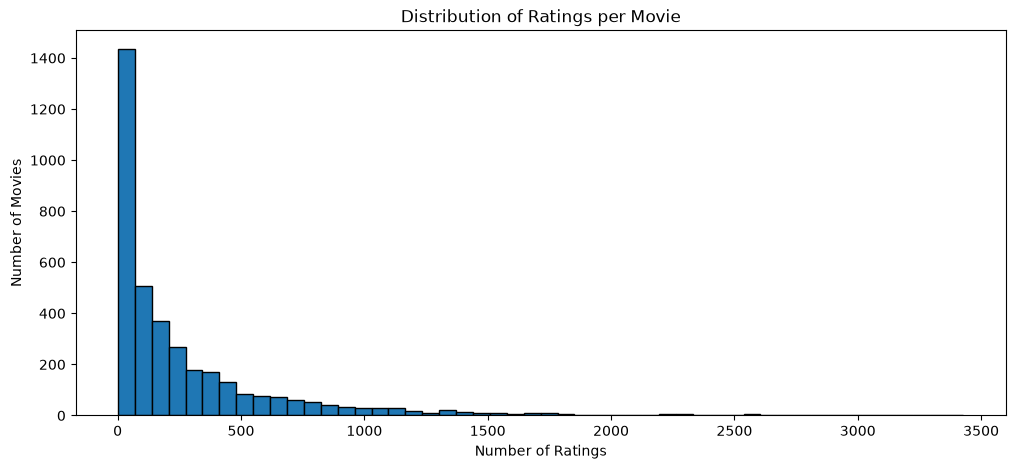

In [54]:
plt.figure(figsize=(12, 5))

plt.hist(ratings_per_movie, bins=50, edgecolor="black")

plt.title("Distribution of Ratings per Movie")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Movies")

plt.show()

In [55]:
ratings_per_movie.sort_values(ascending=False).head(10)


movie_id
2858    3428
260     2991
1196    2990
1210    2883
480     2672
2028    2653
589     2649
2571    2590
1270    2583
593     2578
dtype: int64

In [56]:
top_movies = ratings_per_movie.sort_values(
    ascending=False
).head(10)

top_movies_df = top_movies.reset_index()
top_movies_df.columns = ["movie_id", "rating_count"]

top_movies_df = top_movies_df.merge(
    movies[["movie_id", "title"]],
    on="movie_id",
    how="left"
)

top_movies_df

,movie_id,rating_count,title
0,2858,3428,American Beauty (1999)
1,260,2991,Star Wars: Episode IV - A New Hope (1977)
2,1196,2990,Star Wars: Episode V - The Empire Strikes Back...
3,1210,2883,Star Wars: Episode VI - Return of the Jedi (1983)
4,480,2672,Jurassic Park (1993)
5,2028,2653,Saving Private Ryan (1998)
6,589,2649,Terminator 2: Judgment Day (1991)
7,2571,2590,"Matrix, The (1999)"
8,1270,2583,Back to the Future (1985)
9,593,2578,"Silence of the Lambs, The (1991)"


### Distribution of Ratings per Movie

The dataset contains 3,706 movies.

The average number of ratings per movie is 269.89, while the median is 123.5. The difference between these values indicates a positively skewed distribution.

The first quartile (Q1) is 33, and the third quartile (Q3) is 350. This means that 50% of movies received between 33 and 350 ratings.

The minimum number of ratings is 1, while the most frequently rated movie received 3,428 ratings.

**Conclusion:**

The distribution is strongly right-skewed. Most movies have relatively few ratings, while a small number of popular movies receive significantly more user interactions.

This indicates an imbalance in movie popularity, which is an important characteristic to consider when developing a recommendation system.

In [57]:
n_users = ratings["user_id"].nunique()
n_movies = ratings["movie_id"].nunique()
n_ratings = len(ratings)

print("Number of users:", n_users)
print("Number of movies:", n_movies)
print("Number of ratings:", n_ratings)

Number of users: 6040
Number of movies: 3706
Number of ratings: 1000209


In [58]:
total_possible_ratings = n_users * n_movies

sparsity = 1 - (n_ratings / total_possible_ratings)

print(f"Matrix sparsity: {sparsity:.2%}")

Matrix sparsity: 95.53%


In [59]:
user_item_matrix = ratings.pivot(
    index="user_id",
    columns="movie_id",
    values="rating"
)

print("Matrix shape:", user_item_matrix.shape)

Matrix shape: (6040, 3706)


In [60]:
user_item_matrix.head()

movie_id,1,2,3,4,5,6,7,8,9,10,...,3943,3944,3945,3946,3947,3948,3949,3950,3951,3952
user_id,,,,,,,,,,,,,,,,,,,,,
1,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [61]:
user_item_matrix.isna().sum().sum()

np.int64(21384031)

In [62]:
total_cells = user_item_matrix.shape[0] * user_item_matrix.shape[1]

filled_cells = user_item_matrix.notna().sum().sum()

missing_cells = user_item_matrix.isna().sum().sum()

print("Total cells:", total_cells)
print("Filled cells:", filled_cells)
print("Missing cells:", missing_cells)

print("Check:", filled_cells + missing_cells == total_cells)

Total cells: 22384240
Filled cells: 1000209
Missing cells: 21384031
Check: True


### User-Item Matrix and Sparsity

The User-Item Matrix contains 6,040 users and 3,706 movies, resulting in 22,384,240 possible user-movie interactions.

However, the dataset contains only 1,000,209 actual ratings.

The matrix sparsity is 95.53%, meaning that only 4.47% of all possible user-movie combinations contain ratings.

There are 21,384,031 missing values in the matrix.

**Conclusion:**

The User-Item Matrix is highly sparse. Most users have rated only a small fraction of available movies.

This is a key challenge for collaborative filtering recommendation systems. Matrix Factorization can address this problem by learning latent user and movie factors from the available ratings and using them to estimate missing preferences.

5. Следующий этап - подготовка данных для Matrix Factorization